# Classificação de recomendação em reviews da Steam

Neste notebook construiremos um classificador supervisionado para responder à pergunta:

> **A partir do texto da review, o usuário recomendaria ou não o jogo?**

Usaremos as avaliações preparadas no projeto, armazenadas em `_DadosLimpos/steam_reviews.pkl.gz`. A entrada do modelo será somente o texto da coluna `review`, e o alvo será `voted_up`:

- `True` → `recomenda`;
- `False` → `nao_recomenda`.

O pipeline será: **review → TF-IDF → Regressão Logística → recomendação prevista**.

> O corpus limpo contém reviews em inglês. Portanto, o modelo treinado neste notebook é apropriado para textos em inglês; textos em português exigiriam dados de treino nesse idioma ou um modelo multilíngue.

## 1. Ambiente e bibliotecas

A primeira célula garante as dependências necessárias no kernel atual. Depois de uma instalação ou atualização, reinicie o kernel caso o ambiente solicite.

In [22]:
%pip install pandas matplotlib scikit-learn joblib


[notice] A new release of pip is available: 25.0.1 -> 26.2.1
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [23]:
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from sklearn.dummy import DummyClassifier
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    RocCurveDisplay,
    accuracy_score,
    balanced_accuracy_score,
    classification_report,
    f1_score,
    roc_auc_score,
)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline

RANDOM_STATE = 42
TAMANHO_AMOSTRA = 100_000  # Use None para treinar com todos os registros válidos.

## 2. Carregamento dos dados do projeto

O código procura a raiz do repositório a partir do diretório atual. Assim, o notebook pode ser executado tanto na raiz quanto dentro de `5_Classificacao`.

O pickle contém colunas de tokens e metadados já preparados nas etapas anteriores. Para esta tarefa manteremos apenas as colunas necessárias para inspeção e modelagem.

In [24]:
def localizar_raiz(inicio=Path.cwd()):
    inicio = inicio.resolve()
    for pasta in (inicio, *inicio.parents):
        arquivo = pasta / '_DadosLimpos' / 'steam_reviews.pkl.gz'
        if arquivo.is_file():
            return pasta
    raise FileNotFoundError(
        'Não foi encontrado _DadosLimpos/steam_reviews.pkl.gz. '
        'Execute o notebook dentro do repositório PLN_SteamRecommend.'
    )

RAIZ = localizar_raiz()
CAMINHO_DADOS = RAIZ / '_DadosLimpos' / 'steam_reviews.pkl.gz'

reviews_completas = pd.read_pickle(CAMINHO_DADOS)
colunas_necessarias = [
    'appid', 'game_name', 'review', 'voted_up', 'review_type', 'review_idioma'
]
colunas_ausentes = set(colunas_necessarias) - set(reviews_completas.columns)
if colunas_ausentes:
    raise ValueError(f'Colunas ausentes no arquivo: {sorted(colunas_ausentes)}')

df = reviews_completas[colunas_necessarias].copy()
del reviews_completas

print('Arquivo:', CAMINHO_DADOS)
print('Dimensões carregadas:', df.shape)
df.head()

KeyboardInterrupt: 

## 3. Inspeção inicial

Antes da modelagem, verificamos tipos, valores ausentes, idioma e distribuição do alvo. Também comparamos `review_type` e `voted_up` apenas para auditar os dados.

A coluna `review_type` **não será usada como atributo**: ela foi usada durante a coleta para distinguir avaliações positivas e negativas e praticamente replica o alvo. Incluí-la permitiria ao modelo descobrir a resposta sem analisar o texto, caracterizando vazamento de informação.

In [ ]:
print('Tipos das colunas:')
print(df.dtypes)

print('\nValores ausentes:')
print(df.isna().sum())

print('\nIdiomas:')
print(df['review_idioma'].value_counts(dropna=False))

print('\nDistribuição original de voted_up:')
print(df['voted_up'].value_counts(dropna=False))

Tipos das colunas:
appid            int64
game_name          str
review             str
voted_up          bool
review_type        str
review_idioma      str
dtype: object

Valores ausentes:
appid            0
game_name        0
review           0
voted_up         0
review_type      0
review_idioma    0
dtype: int64

Idiomas:
review_idioma
en    395256
Name: count, dtype: int64

Distribuição original de voted_up:
voted_up
False    206472
True     188784
Name: count, dtype: int64


In [ ]:
tipo_indica_positivo = df['review_type'].eq('positive')
inconsistencias = tipo_indica_positivo.ne(df['voted_up'])

print('Divergências entre review_type e voted_up:', int(inconsistencias.sum()))
df.loc[inconsistencias, ['review_type', 'voted_up', 'review']].head()

Divergências entre review_type e voted_up: 15


,review_type,voted_up,review
6050,negative,True,It’s like falling in love and having the time ...
22612,negative,True,"Game runs fine with vsync on, got it maxed out..."
65219,negative,True,This game hasn't fixed the stun lock mechanics...
76341,positive,False,I'm sorry but the game crashes so much that it...
107737,negative,True,Honestly this game would benefit from being ab...


## 4. Preparação para a classificação

A preparação aplicada nesta etapa é deliberadamente simples:

- remover registros sem texto ou rótulo;
- normalizar espaços em branco;
- remover textos vazios;
- descartar textos idênticos com rótulos conflitantes;
- manter uma única ocorrência de cada texto, evitando que a mesma review apareça no treino e no teste;
- converter o alvo booleano para nomes legíveis;
- selecionar, opcionalmente, uma amostra estratificada.

Não removeremos stopwords. Termos como `not`, `never` e construções como `do not recommend` são importantes para a decisão.

In [ ]:
df = df.dropna(subset=['review', 'voted_up']).copy()
df['review'] = (
    df['review']
    .astype(str)
    .str.replace(r'\s+', ' ', regex=True)
    .str.strip()
)
df = df[df['review'].str.len() > 0].copy()

# Remove textos iguais associados simultaneamente às duas classes.
rotulos_por_texto = df.groupby('review', sort=False)['voted_up'].transform('nunique')
quantidade_conflitante = int(rotulos_por_texto.gt(1).sum())
df = df.loc[rotulos_por_texto.eq(1)].drop_duplicates(subset='review').copy()

df['recomendacao'] = df['voted_up'].map(
    {False: 'nao_recomenda', True: 'recomenda'}
)

if TAMANHO_AMOSTRA is not None and len(df) > TAMANHO_AMOSTRA:
    df, _ = train_test_split(
        df,
        train_size=TAMANHO_AMOSTRA,
        random_state=RANDOM_STATE,
        stratify=df['recomendacao'],
    )
    df = df.reset_index(drop=True)

print('Ocorrências removidas por conflito de rótulo:', quantidade_conflitante)
print('Registros usados:', len(df))
print(df['recomendacao'].value_counts())

Ocorrências removidas por conflito de rótulo: 295
Registros usados: 100000
recomendacao
nao_recomenda    52389
recomenda        47611
Name: count, dtype: int64


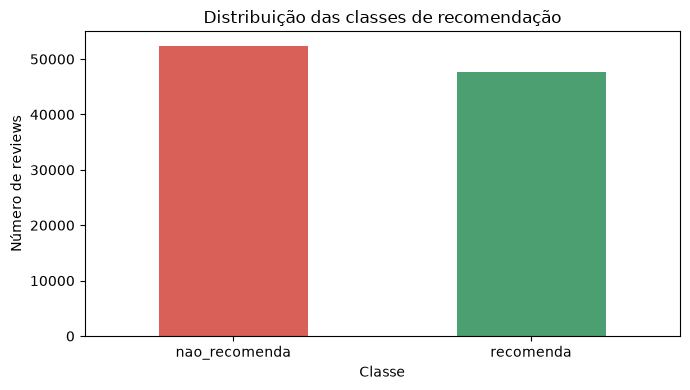

In [ ]:
ordem_classes = ['nao_recomenda', 'recomenda']
contagens = df['recomendacao'].value_counts().reindex(ordem_classes)

ax = contagens.plot(kind='bar', figsize=(7, 4), color=['#d95f59', '#4c9f70'])
ax.set_title('Distribuição das classes de recomendação')
ax.set_xlabel('Classe')
ax.set_ylabel('Número de reviews')
ax.tick_params(axis='x', rotation=0)
plt.tight_layout()
plt.show()

## 5. Separação entre treino e teste

Usaremos 80% dos textos para treinamento e 20% para teste. O parâmetro `stratify` preserva aproximadamente a proporção das classes nos dois conjuntos.

Toda a transformação TF-IDF será ajustada somente no conjunto de treino, pois ela está dentro do `Pipeline`.

In [ ]:
X = df['review']
y = df['recomendacao']

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y,
)

print('Treino:', len(X_train))
print('Teste:', len(X_test))
print('\nProporções no treino:')
print(y_train.value_counts(normalize=True).sort_index())
print('\nProporções no teste:')
print(y_test.value_counts(normalize=True).sort_index())

Treino: 80000
Teste: 20000

Proporções no treino:
recomendacao
nao_recomenda    0.523887
recomenda        0.476112
Name: proportion, dtype: float64

Proporções no teste:
recomendacao
nao_recomenda    0.5239
recomenda        0.4761
Name: proportion, dtype: float64


## 6. Baseline

Antes do modelo textual, treinamos um classificador ingênuo que sempre escolhe a classe mais frequente. O modelo TF-IDF só será útil se superar claramente essa referência.

In [ ]:
baseline = DummyClassifier(strategy='most_frequent')
baseline.fit(X_train.to_frame(), y_train)
pred_baseline = baseline.predict(X_test.to_frame())

print(f'Acurácia do baseline: {accuracy_score(y_test, pred_baseline):.3f}')
print(f'F1 macro do baseline: {f1_score(y_test, pred_baseline, average="macro"):.3f}')

Acurácia do baseline: 0.524
F1 macro do baseline: 0.344


## 7. TF-IDF + Regressão Logística

O `TfidfVectorizer` transforma os textos em uma matriz numérica esparsa. Serão usados unigramas e bigramas, permitindo representar tanto palavras isoladas (`great`, `broken`) quanto expressões (`not worth`, `highly recommend`).

A Regressão Logística produz a classe prevista e uma probabilidade estimada para cada classe. `class_weight='balanced'` torna o treinamento mais robusto caso a proporção das classes mude em versões futuras dos dados.

In [ ]:
modelo = Pipeline([
    (
        'tfidf',
        TfidfVectorizer(
            lowercase=True,
            strip_accents='unicode',
            min_df=3,
            max_df=0.98,
            ngram_range=(1, 2),
            max_features=40_000,
            sublinear_tf=True,
            dtype=np.float32,
        ),
    ),
    (
        'classificador',
        LogisticRegression(
            max_iter=1000,
            class_weight='balanced',
            random_state=RANDOM_STATE,
        ),
    ),
])

modelo.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('tfidf', ...), ('classificador', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[object](2,)","['nao_recomenda','recomenda']"
,"strip_accents strip_accents: {'ascii', 'unicode'} or callable, default=NoneRemove accents and perform other character normalizationduring the preprocessing step.'ascii' is a fast method that only works on characters that havea direct ASCII mapping.'unicode' is a slightly slower method that works on any characters.None (default) means no character normalization is performed.Both 'ascii' and 'unicode' use NFKD normalization from:func:`unicodedata.normalize`.",'unicode'
,"ngram_range ngram_range: tuple (min_n, max_n), default=(1, 1)The lower and upper boundary of the range of n-values for differentn-grams to be extracted. All values of n such that min_n <= n <= max_nwill be used. For example an ``ngram_range`` of ``(1, 1)`` means onlyunigrams, ``(1, 2)`` means unigrams and bigrams, and ``(2, 2)`` meansonly bigrams.Only applies if ``analyzer`` is not callable.","(1, ...)"
,"max_df max_df: float or int, default=1.0When building the vocabulary ignore terms that have a documentfrequency strictly higher than the given threshold (corpus-specificstop words).If float in range [0.0, 1.0], the parameter represents a proportion ofdocuments, integer absolute counts.This parameter is ignored if vocabulary is not None.",0.98
,"min_df min_df: float or int, default=1When building the vocabulary ignore terms that have a documentfrequency strictly lower than the given threshold. This value is alsocalled cut-off in the literature.If float in range of [0.0, 1.0], the parameter represents a proportionof documents, integer absolute counts.This parameter is ignored if vocabulary is not None.",3
,"max_features max_features: int, default=NoneIf not None, build a vocabulary that only consider the top`max_features` ordered by term frequency across the corpus.Otherwise, all features are used.This parameter is ignored if vocabulary is not None.",40000


## 8. Avaliação

Além da acurácia, examinaremos:

- **acurácia balanceada**, que atribui o mesmo peso ao recall de cada classe;
- **precision**, proporção de previsões de uma classe que estavam corretas;
- **recall**, proporção dos casos reais de uma classe encontrados pelo modelo;
- **F1-score**, média harmônica entre precision e recall;
- **ROC-AUC**, capacidade de ordenar reviews positivas acima das negativas em diferentes limiares.

In [ ]:
y_pred = modelo.predict(X_test)
probabilidades = modelo.predict_proba(X_test)
classes_modelo = modelo.named_steps['classificador'].classes_
indice_recomenda = int(np.where(classes_modelo == 'recomenda')[0][0])
prob_recomenda = probabilidades[:, indice_recomenda]

print(f'Acurácia: {accuracy_score(y_test, y_pred):.3f}')
print(f'Acurácia balanceada: {balanced_accuracy_score(y_test, y_pred):.3f}')
print(f'F1 macro: {f1_score(y_test, y_pred, average="macro"):.3f}')
print(
    'ROC-AUC:',
    f'{roc_auc_score(y_test.eq("recomenda"), prob_recomenda):.3f}',
)
print('\nRelatório por classe:\n')
print(classification_report(y_test, y_pred, labels=ordem_classes, digits=3))

Acurácia: 0.875
Acurácia balanceada: 0.875
F1 macro: 0.875
ROC-AUC: 0.945

Relatório por classe:

               precision    recall  f1-score   support

nao_recomenda      0.880     0.882     0.881     10478
    recomenda      0.870     0.867     0.868      9522

     accuracy                          0.875     20000
    macro avg      0.875     0.875     0.875     20000
 weighted avg      0.875     0.875     0.875     20000



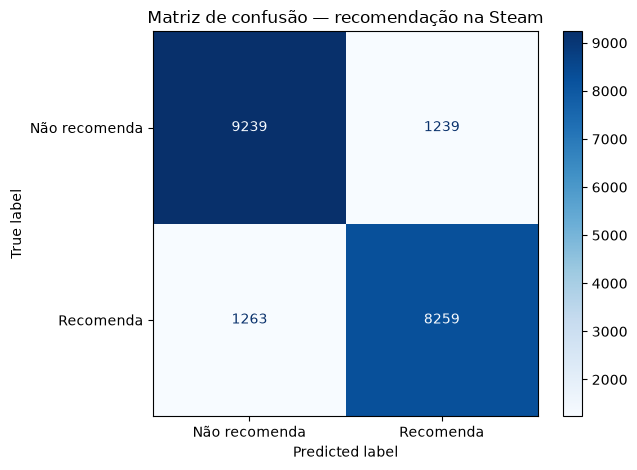

In [ ]:
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    labels=ordem_classes,
    display_labels=['Não recomenda', 'Recomenda'],
    cmap='Blues',
    values_format='d',
)
plt.title('Matriz de confusão — recomendação na Steam')
plt.tight_layout()
plt.show()

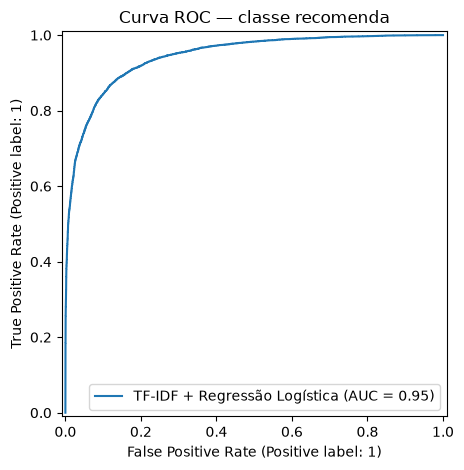

In [ ]:
RocCurveDisplay.from_predictions(
    y_test.eq('recomenda'),
    prob_recomenda,
    name='TF-IDF + Regressão Logística',
)
plt.title('Curva ROC — classe recomenda')
plt.tight_layout()
plt.show()

## 9. Termos associados às decisões

Na classificação binária do `scikit-learn`, os coeficientes da Regressão Logística favorecem `classes_[1]` quando são positivos e `classes_[0]` quando são negativos.

Esses coeficientes representam associações aprendidas no corpus, não relações causais. Nomes de jogos, memes ou padrões da coleta também podem aparecer entre os termos mais fortes.

In [ ]:
vetorizador = modelo.named_steps['tfidf']
classificador = modelo.named_steps['classificador']
termos = vetorizador.get_feature_names_out()
coeficientes = classificador.coef_[0]

coef_df = pd.DataFrame({
    'termo': termos,
    'coeficiente': coeficientes,
}).sort_values('coeficiente')

print('Ordem das classes:', classificador.classes_)

Ordem das classes: ['nao_recomenda' 'recomenda']


In [ ]:
print('Termos mais associados a NÃO RECOMENDAR:')
coef_df.head(20)

Termos mais associados a NÃO RECOMENDAR:


,termo,coeficiente
5221,boring,-9.421995
22691,not worth,-8.275634
22468,not,-7.856353
22291,no,-7.431820
6180,can recommend,-6.636167
36566,unfortunately,-5.956088
22545,not fun,-5.867690
22635,not recommend,-5.709980
27326,refund,-5.642478
36686,unplayable,-5.612128


In [ ]:
print('Termos mais associados a RECOMENDAR:')
coef_df.tail(20).sort_values('coeficiente', ascending=False)

Termos mais associados a RECOMENDAR:


,termo,coeficiente
12891,fun,7.964231
14476,great,7.621561
10,10 10,6.263301
14232,good,6.253998
22490,not bad,5.932926
19961,love,5.803849
1391,amazing,5.470039
29870,solid,5.098642
22671,not too,4.967098
8515,definitely,4.884317


## 10. Análise dos erros

Reviews mistas, ironia, sarcasmo, comparações e mudanças de opinião são casos difíceis para um modelo linear. A tabela abaixo destaca erros de alta confiança, úteis para encontrar limitações do modelo ou ruído nos rótulos.

In [ ]:
resultados_teste = pd.DataFrame({
    'review': X_test.to_numpy(),
    'real': y_test.to_numpy(),
    'previsto': y_pred,
    'prob_recomenda': prob_recomenda,
    'confianca': probabilidades.max(axis=1),
})

erros = (
    resultados_teste[resultados_teste['real'] != resultados_teste['previsto']]
    .sort_values('confianca', ascending=False)
)

print('Quantidade de erros:', len(erros))
erros.head(15)

Quantidade de erros: 2502


,review,real,previsto,prob_recomenda,confianca
19498,Updated Review: So after the devs finally deci...,recomenda,nao_recomenda,0.006850,0.993150
5890,If I could give a mixed review instead of a go...,recomenda,nao_recomenda,0.011074,0.988926
18969,[h1]🎮 Eight Mini Racers 🌟[/h1] [b]📌 Quick Over...,nao_recomenda,recomenda,0.987453,0.987453
3558,"Graphics look weird, settings don't seem to ta...",recomenda,nao_recomenda,0.013610,0.986390
18427,"very good game, have sex simulator and hazard ...",nao_recomenda,recomenda,0.984994,0.984994
572,I refunded it. Then I bought it again. Out of ...,recomenda,nao_recomenda,0.017073,0.982927
13125,Soft pass. I don't think it's anything wrong w...,recomenda,nao_recomenda,0.019603,0.980397
17591,Well im not gonna leave a bad review cus ithin...,recomenda,nao_recomenda,0.020906,0.979093
17599,"My favorite genre is shoot'em up, but I have m...",nao_recomenda,recomenda,0.977922,0.977922
18345,You should start with the tutorial because thi...,recomenda,nao_recomenda,0.023394,0.976606


In [ ]:
print('Falsos positivos: modelo previu RECOMENDA, mas o usuário não recomendou')
erros[
    (erros['real'] == 'nao_recomenda')
    & (erros['previsto'] == 'recomenda')
].head(10)

Falsos positivos: modelo previu RECOMENDA, mas o usuário não recomendou


,review,real,previsto,prob_recomenda,confianca
18969,[h1]🎮 Eight Mini Racers 🌟[/h1] [b]📌 Quick Over...,nao_recomenda,recomenda,0.987453,0.987453
18427,"very good game, have sex simulator and hazard ...",nao_recomenda,recomenda,0.984994,0.984994
17599,"My favorite genre is shoot'em up, but I have m...",nao_recomenda,recomenda,0.977922,0.977922
18700,"I wish the performance issues were fixed, espe...",nao_recomenda,recomenda,0.967311,0.967311
19033,"World Ship Simulator, developed by Odin Game S...",nao_recomenda,recomenda,0.966184,0.966184
12218,A perfectly fine game. I can't say I loved it ...,nao_recomenda,recomenda,0.962005,0.962005
11124,Tiny Terraces is a charming little idle farmin...,nao_recomenda,recomenda,0.953406,0.953406
4695,It’s very easy to see how Maniac Mansion becam...,nao_recomenda,recomenda,0.950508,0.950508
14644,I would actually recommend this to others.... ...,nao_recomenda,recomenda,0.948467,0.948467
8689,im also killing myself 10/10 beating this game...,nao_recomenda,recomenda,0.945499,0.945499


In [ ]:
print('Falsos negativos: modelo previu NÃO RECOMENDA, mas o usuário recomendou')
erros[
    (erros['real'] == 'recomenda')
    & (erros['previsto'] == 'nao_recomenda')
].head(10)

Falsos negativos: modelo previu NÃO RECOMENDA, mas o usuário recomendou


,review,real,previsto,prob_recomenda,confianca
19498,Updated Review: So after the devs finally deci...,recomenda,nao_recomenda,0.006850,0.993150
5890,If I could give a mixed review instead of a go...,recomenda,nao_recomenda,0.011074,0.988926
3558,"Graphics look weird, settings don't seem to ta...",recomenda,nao_recomenda,0.013610,0.986390
572,I refunded it. Then I bought it again. Out of ...,recomenda,nao_recomenda,0.017073,0.982927
13125,Soft pass. I don't think it's anything wrong w...,recomenda,nao_recomenda,0.019603,0.980397
17591,Well im not gonna leave a bad review cus ithin...,recomenda,nao_recomenda,0.020906,0.979093
18345,You should start with the tutorial because thi...,recomenda,nao_recomenda,0.023394,0.976606
2780,It's getting harder to write reviews for some ...,recomenda,nao_recomenda,0.027613,0.972387
6634,Not a bad game it's just kinda bland I'm gonna...,recomenda,nao_recomenda,0.028198,0.971802
19029,"-The concept is neat, but the execution left s...",recomenda,nao_recomenda,0.029859,0.970141


## 11. Classificando novas reviews

A função abaixo recebe textos em inglês e retorna a classe prevista e a probabilidade estimada de recomendação. A probabilidade é uma confiança do modelo, não uma garantia de que o usuário realmente faria a recomendação.

In [25]:
def classificar_reviews(textos):
    textos = list(textos)
    previsoes = modelo.predict(textos)
    proba = modelo.predict_proba(textos)[:, indice_recomenda]
    return pd.DataFrame({
        'review': textos,
        'classe_prevista': previsoes,
        'prob_recomenda': proba,
    })

novas_reviews = [
    'Amazing game, fun with friends and absolutely worth the price.',
    'The game crashes constantly and I cannot recommend it.',
    'It has some problems, but I still had a great time playing it.',
    'Beautiful graphics, terrible controls and boring gameplay.',
    'Not perfect, yet I would definitely recommend it on sale.',
    'Great game, I highly recommend it if you like getting beaten up like a son of a bitch and then coming back to get beaten up again.'
]

classificar_reviews(novas_reviews)

,review,classe_prevista,prob_recomenda
0,"Amazing game, fun with friends and absolutely ...",recomenda,0.996199
1,The game crashes constantly and I cannot recom...,nao_recomenda,0.016105
2,"It has some problems, but I still had a great ...",recomenda,0.962297
3,"Beautiful graphics, terrible controls and bori...",nao_recomenda,0.022578
4,"Not perfect, yet I would definitely recommend ...",recomenda,0.993016
5,"Great game, I highly recommend it if you like ...",recomenda,0.964814


## 12. Salvando o pipeline treinado

O pipeline contém o vocabulário TF-IDF e o classificador. Ative a opção abaixo para reutilizá-lo sem novo treinamento. Carregue arquivos `joblib` apenas quando sua origem for confiável.

In [ ]:
SALVAR_MODELO = False
CAMINHO_MODELO = RAIZ / '5_Classificacao' / 'modelo_recomendacao_tfidf.joblib'

if SALVAR_MODELO:
    CAMINHO_MODELO.parent.mkdir(parents=True, exist_ok=True)
    joblib.dump(modelo, CAMINHO_MODELO)
    print('Modelo salvo em:', CAMINHO_MODELO)
else:
    print('Modelo não salvo. Defina SALVAR_MODELO = True para exportá-lo.')

Modelo não salvo. Defina SALVAR_MODELO = True para exportá-lo.


## 13. Limitações e próximos passos

Este notebook estabelece um baseline interpretável para o projeto. Algumas limitações importantes são:

- o modelo aprende correlações lexicais e tem dificuldade com ironia, contexto longo e opiniões mistas;
- o corpus atual contém somente textos identificados como inglês;
- a probabilidade da Regressão Logística não foi calibrada separadamente;
- avaliações coletadas em momentos ou jogos diferentes podem ter distribuições distintas;
- o resultado estima a recomendação expressa pelo autor, não a qualidade objetiva do jogo.

Próximos experimentos possíveis:

1. comparar TF-IDF + Regressão Logística com `LinearSVC`;
2. medir desempenho por jogo e por tamanho da review;
3. separar jogos inteiros entre treino e teste para avaliar generalização a títulos não vistos;
4. calibrar probabilidades;
5. comparar com embeddings ou modelos Transformers;
6. coletar reviews em português para um classificador específico desse idioma.

## Referências

- Scikit-learn — Working with text data: https://scikit-learn.org/stable/tutorial/text_analytics/working_with_text_data.html
- Scikit-learn — `TfidfVectorizer`: https://scikit-learn.org/stable/modules/generated/sklearn.feature_extraction.text.TfidfVectorizer.html
- Scikit-learn — `LogisticRegression`: https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LogisticRegression.html
- Steamworks — User Reviews: https://partner.steamgames.com/doc/store/reviews